In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchvision

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Environment setup successful!")

NumPy: 2.5.4
Pandas: 3.0.6
PyTorch: 2.14.1+cpu
CUDA available: False
Environment setup successful!


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("../data/processed")

train = pd.read_csv(root / "train_labels.csv")
validation = pd.read_csv(root / "validation_labels.csv")
test = pd.read_csv(root / "test_labels.csv")

products = [
    "B00O4OR4GQ",
    "B013UJS35G",
    "B0159A0LH2",
    "B019D9HESO",
    "B01B1GE6KG",
]

print("Dataset sizes:")
print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

print("\nProduct presence in training data:")
print((train[[f"qty_{p}" for p in products]] > 0).sum())

print("\nQuantity distribution in training data:")
print(train[[f"qty_{p}" for p in products]].sum())

Dataset sizes:
Train: 1400
Validation: 200
Test: 200

Product presence in training data:
qty_B00O4OR4GQ    210
qty_B013UJS35G    350
qty_B0159A0LH2    169
qty_B019D9HESO    173
qty_B01B1GE6KG    168
dtype: int64

Quantity distribution in training data:
qty_B00O4OR4GQ    319
qty_B013UJS35G    372
qty_B0159A0LH2    173
qty_B019D9HESO    244
qty_B01B1GE6KG    225
dtype: int64


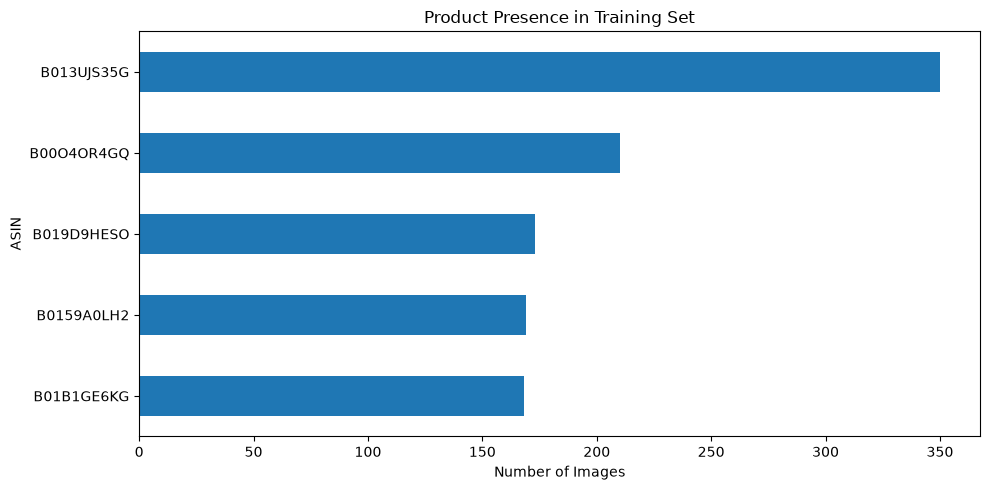

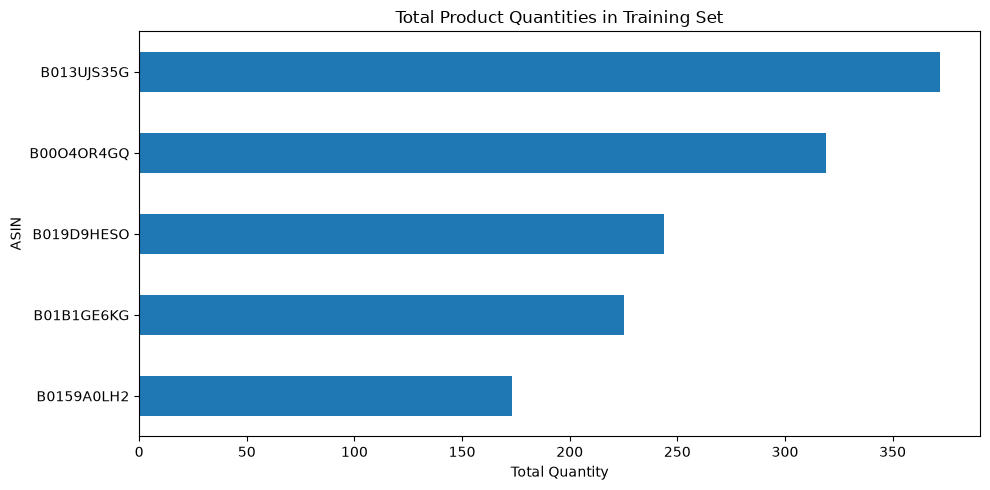

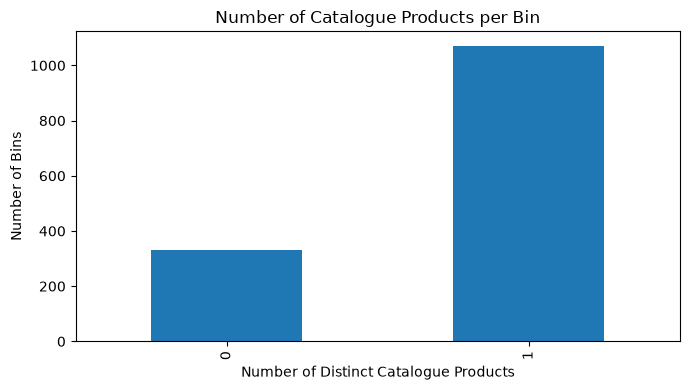

In [2]:
import matplotlib.pyplot as plt

# 1. Number of training images containing each product
presence = (train[[f"qty_{p}" for p in products]] > 0).sum()
presence.index = [p.replace("qty_", "") for p in presence.index]

plt.figure(figsize=(10, 5))
presence.sort_values().plot(kind="barh")
plt.title("Product Presence in Training Set")
plt.xlabel("Number of Images")
plt.ylabel("ASIN")
plt.tight_layout()
plt.show()


# 2. Total quantity of each product in the training set
quantities = train[[f"qty_{p}" for p in products]].sum()
quantities.index = [p.replace("qty_", "") for p in quantities.index]

plt.figure(figsize=(10, 5))
quantities.sort_values().plot(kind="barh")
plt.title("Total Product Quantities in Training Set")
plt.xlabel("Total Quantity")
plt.ylabel("ASIN")
plt.tight_layout()
plt.show()


# 3. Distribution of the number of catalogue products per bin
product_counts = (train[[f"qty_{p}" for p in products]] > 0).sum(axis=1)

plt.figure(figsize=(7, 4))
product_counts.value_counts().sort_index().plot(kind="bar")
plt.title("Number of Catalogue Products per Bin")
plt.xlabel("Number of Distinct Catalogue Products")
plt.ylabel("Number of Bins")
plt.tight_layout()
plt.show()

In [3]:
# Total quantity of the five catalogue products in each bin
qty_columns = [f"qty_{p}" for p in products]

train["total_catalogue_quantity"] = train[qty_columns].sum(axis=1)

print("Total catalogue quantity per bin:")
print(train["total_catalogue_quantity"].describe())

print("\nDistribution of total catalogue quantity:")
print(
    train["total_catalogue_quantity"]
    .value_counts()
    .sort_index()
)

# Check bins containing more than one distinct catalogue product
product_counts = (train[qty_columns] > 0).sum(axis=1)

print("\nBins containing multiple catalogue products:")
print((product_counts > 1).sum())

# Check bins with no catalogue products
print("Bins with no catalogue products:", (product_counts == 0).sum())

Total catalogue quantity per bin:
count    1400.000000
mean        0.952143
std         0.716293
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         5.000000
Name: total_catalogue_quantity, dtype: float64

Distribution of total catalogue quantity:
total_catalogue_quantity
0    330
1    858
2    173
3     28
4     10
5      1
Name: count, dtype: int64

Bins containing multiple catalogue products:
0
Bins with no catalogue products: 330


In [4]:
import sqlite3
import json

DB_PATH = r"D:\smart bin dataset\metadata.db"

qty_columns = [f"qty_{p}" for p in products]
zero_bins = train.loc[
    train[qty_columns].sum(axis=1) == 0, "filename"
].head(10)

conn = sqlite3.connect(DB_PATH)

for filename in zero_bins:
    row = conn.execute(
        "SELECT metadata FROM metadata WHERE name = ?",
        (filename,)
    ).fetchone()

    print(f"\nImage: {filename}")

    if row is None:
        print("NOT FOUND in original metadata")
        continue

    metadata = json.loads(row[0])
    print("Expected quantity:", metadata.get("EXPECTED_QUANTITY"))
    print("Original product data:", metadata.get("BIN_FCSKU_DATA"))

conn.close()


Image: 355068.jpg
Expected quantity: 4
Original product data: {'B000KMZKTO': {'asin': 'B000KMZKTO', 'height': {'unit': 'IN', 'value': 2.1999999977560005}, 'length': {'unit': 'IN', 'value': 9.49999999031}, 'name': 'RCA RD-1006 Discwasher Vinyl Record Care System', 'normalizedName': 'RCA RD-1006 Discwasher Vinyl Record Care System', 'quantity': 1, 'weight': {'unit': 'pounds', 'value': 0.4999999995807047}, 'width': {'unit': 'IN', 'value': 7.199999992656}}, 'B00400098Y': {'asin': 'B00400098Y', 'height': {'unit': 'IN', 'value': 2.199999997756}, 'length': {'unit': 'IN', 'value': 5.799999994084}, 'name': '5" x 8", 4 Mil (Heavy Duty) White Block Zipper Reclosable Storage Bags, DispenserBag Pack of 100', 'normalizedName': 'Pack of 100 5" x 8", 4 Mil (Heavy Duty) White Block Zipper Reclosable Storage Bags, DispenserBag', 'quantity': 3, 'weight': {'unit': 'pounds', 'value': 1.35}, 'width': {'unit': 'IN', 'value': 5.399999994492}}}

Image: 246242.jpg
Expected quantity: 5
Original product data: {'

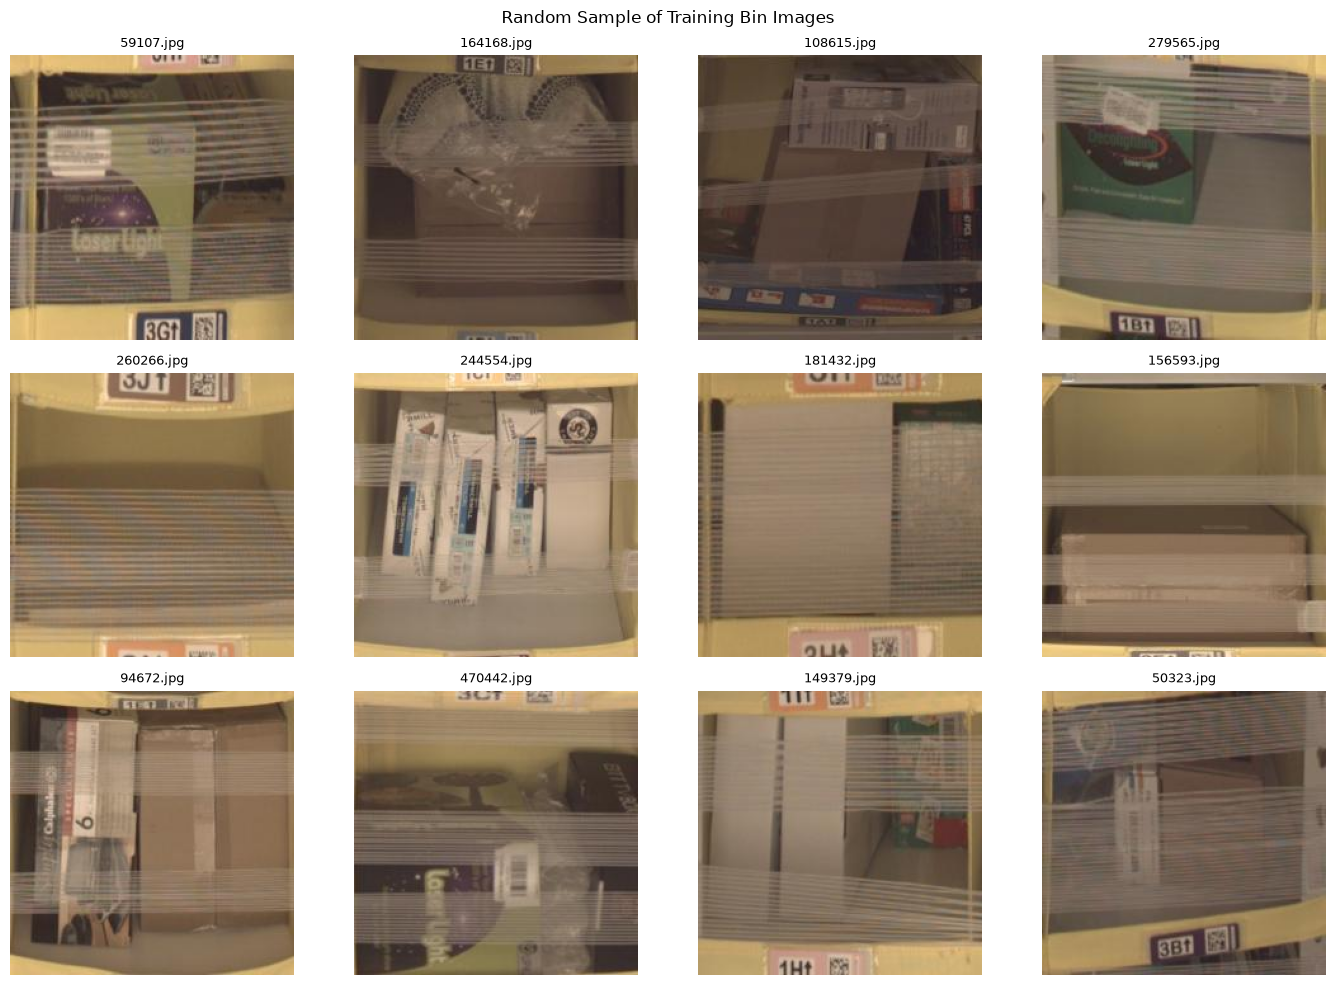

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
import random
from pathlib import Path

image_dir = Path("../data/processed/train")

random.seed(42)
image_files = random.sample(
    list(image_dir.glob("*.jpg")),
    12
)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, image_path in zip(axes.flat, image_files):
    img = Image.open(image_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(image_path.name, fontsize=9)
    ax.axis("off")

plt.suptitle("Random Sample of Training Bin Images")
plt.tight_layout()
plt.show()

## Image Quality Analysis

A random sample of 12 training images was visually inspected.

**Observations**
- Horizontal transparent tape crosses the images and obscures parts of the products.
- Some products are partially hidden by other items or packaging.
- Lighting and contrast vary across images.
- Cardboard boxes and similar packaging make visual identification challenging.
- Some bins appear empty or contain no clearly identifiable catalogue products.

**Implications**
These conditions may reduce product-presence and quantity-prediction accuracy. The images were retained because tape and occlusion are characteristics of the supplied warehouse data. Performance will be evaluated on a separate test set, and representative incorrect predictions will be examined during failure analysis.

**Limitation**
This was a qualitative inspection of 12 randomly sampled images, not a complete quantitative assessment of image quality.

Product presence by split:
            Train  Validation  Test
B00O4OR4GQ    210          25    38
B013UJS35G    350          45    35
B0159A0LH2    169          33    30
B019D9HESO    173          28    19
B01B1GE6KG    168          19    31


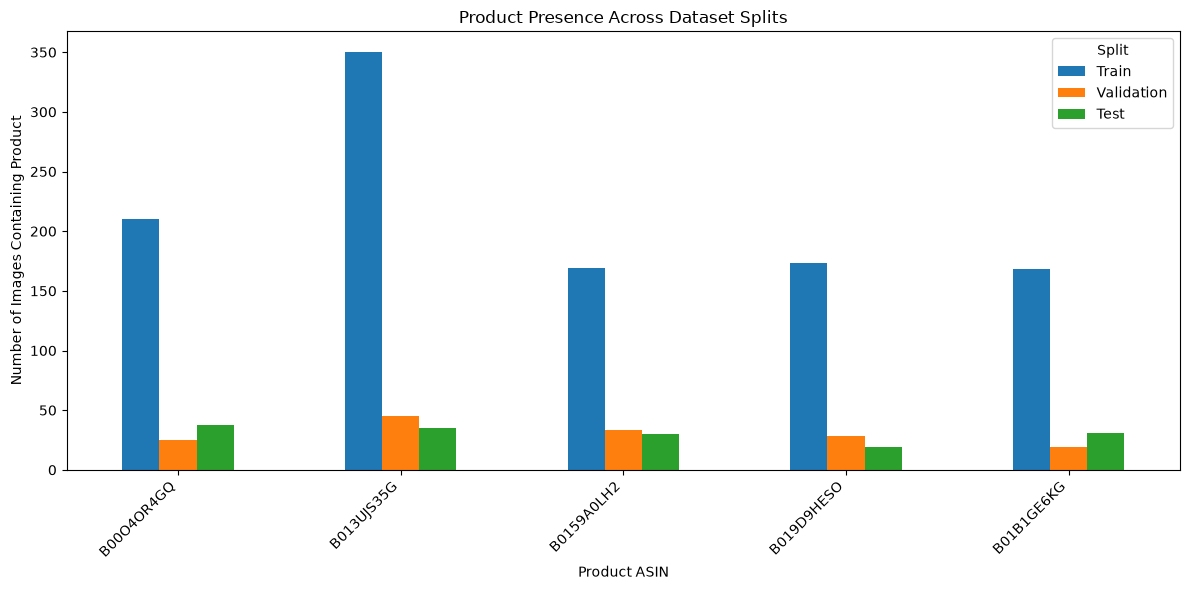

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("../data/processed")

splits = {
    "Train": pd.read_csv(root / "train_labels.csv"),
    "Validation": pd.read_csv(root / "validation_labels.csv"),
    "Test": pd.read_csv(root / "test_labels.csv"),
}

qty_columns = [f"qty_{p}" for p in products]

# Count images containing each product in each split
presence_counts = pd.DataFrame({
    name: (df[qty_columns] > 0).sum()
    for name, df in splits.items()
})

presence_counts.index = [
    col.replace("qty_", "") for col in presence_counts.index
]

print("Product presence by split:")
print(presence_counts)

# Compare product presence across splits
presence_counts.plot(kind="bar", figsize=(12, 6))
plt.title("Product Presence Across Dataset Splits")
plt.xlabel("Product ASIN")
plt.ylabel("Number of Images Containing Product")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Split")
plt.tight_layout()
plt.show()